1. Judul Kasus

"Perancangan Dasbor Pemantauan Epidemiologi & Kesiapsiagaan Rumah Sakit Kota Berbasis Psikologi Kognitif dan Prinsip Shneiderman (HealthViz-HCI)"

2. Deskripsi Masalah & Profil Pengguna (Persona)
Konteks Masalah: Dinas Kesehatan Kota menghadapi kendala saat memantau lonjakan kasus penyakit menular musiman (seperti Demam Berdarah Dengue / DBD) serta tingkat keterisian tempat tidur rumah sakit (Bed Occupancy Rate / BOR). Dasbor lama ditolak oleh pimpinan dinas karena mengalami masalah Extraneous Cognitive Load: penuh dengan tabel angka panjang tanpa hierarki warna, menggunakan grafik 3D (chartjunk) yang mendistorsi data, lambat saat memfilter wilayah, dan tidak ramah pengguna.
Target Persona (Budi / Dr. Rina - Kepala Bidang P2P Dinas Kesehatan):
Demografi: Usia 45 tahun, memiliki waktu terbatas, sering mengakses dasbor melalui tablet di tengah rapat tanggap darurat.
Goals: Memantau kapasitas rumah sakit yang berada dalam kondisi darurat/kritis dalam waktu kurang dari 5 detik, serta mengidentifikasi tren kasus mingguan untuk alokasi logistik obat dan tenaga medis.
Pain Points: Lelah membaca tabel spreadsheet numerik; sering salah menafsirkan grafik warna-warni yang membingungkan.

[BERHASIL] Gambar visualisasi statis tersimpan sebagai 'healthviz_dashboard_static.png'.
[BERHASIL] Aplikasi Web Dasbor Interaktif tersimpan sebagai 'healthviz_dashboard_interactive.html'.


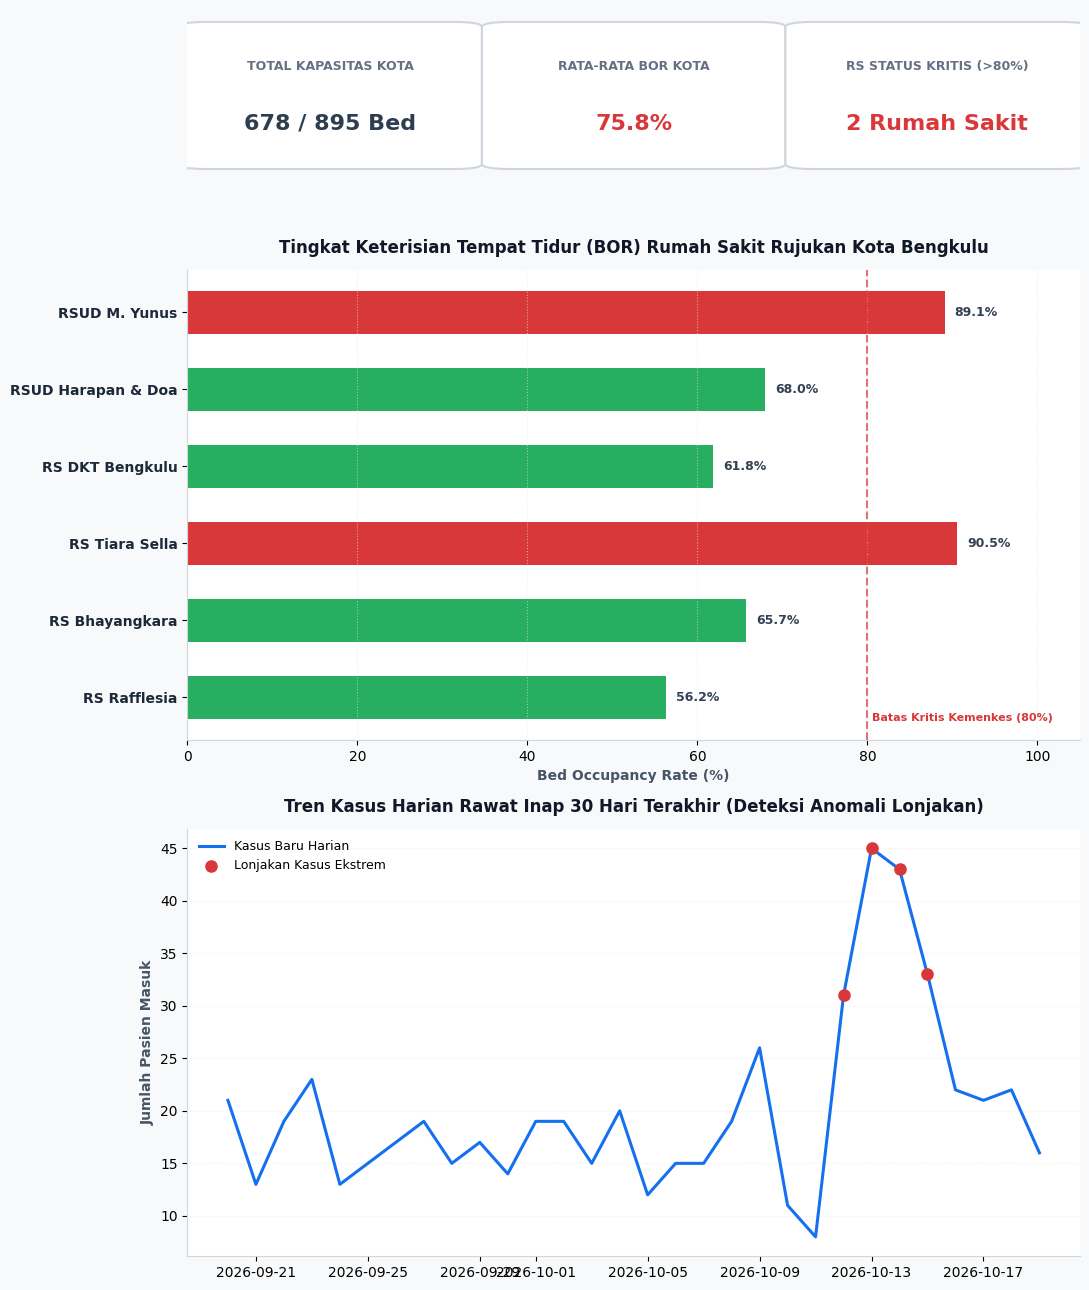

In [1]:
"""
SISTEM HEALTHVIZ-HCI: DASBOR PEMANTAUAN EPIDEMIOLOGI & FASILITAS KESEHATAN KOTA
Mengimplementasikan Prinsip-Prinsip Kuliah Praktisi Dr. Arafat Febriandirza (BRIN):
1. Shneiderman's Mantra (Overview first, Zoom & Filter, Details-on-Demand)
2. Edward Tufte's High Data-Ink Ratio (Zero Chartjunk, Minimalist Clean Grid)
3. Preattentive Attributes (Warna merah khusus untuk anomali/kritis > 80% BOR)
4. Gestalt Principles (Proximity, Similarity, and Enclosure)
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# ==============================================================================
# 1. PENGUMPULAN & PENYIAPAN DATASET SINTETIS (DATA UNDERSTANDING)
# ==============================================================================
np.random.seed(42)

# Data Kapasitas Rumah Sakit Rujukan di Kota Bengkulu
hospital_data = {
    'Nama_RS': ['RSUD M. Yunus', 'RSUD Harapan & Doa', 'RS DKT Bengkulu',
                'RS Tiara Sella', 'RS Bhayangkara', 'RS Rafflesia'],
    'Wilayah': ['Gading Cempaka', 'Ratu Agung', 'Teluk Segara',
                'Ratu Samban', 'Selebar', 'Gading Cempaka'],
    'Total_Bed': [320, 150, 110, 95, 140, 80],
    'Bed_Terisi': [285, 102, 68, 86, 92, 45]
}

df_rs = pd.DataFrame(hospital_data)
df_rs['BOR_Persen'] = (df_rs['Bed_Terisi'] / df_rs['Total_Bed']) * 100

# Menentukan Status Berdasarkan Preattentive Visual Attributes
def tentukan_status(bor):
    if bor >= 80.0:
        return 'Kritis', '#D9383A'      # Merah menyala (Preattentive Alert)
    elif bor >= 70.0:
        return 'Waspada', '#F39C12'     # Kuning/Oranye (Peringatan)
    else:
        return 'Aman', '#27AE60'        # Hijau/Netral (Normal)

df_rs['Status'], df_rs['Warna'] = zip(*df_rs['BOR_Persen'].apply(tentukan_status))

# Data Tren Kasus DBD Harian Selama 30 Hari Terakhir
dates = pd.date_range(start='2026-09-20', periods=30, freq='D')
trend_cases = np.random.poisson(lam=18, size=30)
trend_cases[22:26] += np.array([15, 22, 28, 20])  # Anomali lonjakan kasus DBD
df_trend = pd.DataFrame({'Tanggal': dates, 'Kasus_Baru': trend_cases})


# ==============================================================================
# 2. IMPLEMENTASI VISUALISASI BERSIH TUFTE & GESTALT (MATPLOTLIB)
# ==============================================================================
fig, (ax_kpi, ax_bar, ax_line) = plt.subplots(3, 1, figsize=(11, 13),
                                              gridspec_kw={'height_ratios': [0.8, 2.2, 2.0]})
fig.patch.set_facecolor('#F8F9FA')  # Latar belakang bersih dan tenang

# --- PANEL 1: OVERVIEW FIRST (KARTU METRIK KPI RINGKAS) ---
ax_kpi.axis('off')
total_bed = df_rs['Total_Bed'].sum()
total_terisi = df_rs['Bed_Terisi'].sum()
bor_kota = (total_terisi / total_bed) * 100
rs_kritis = (df_rs['Status'] == 'Kritis').sum()

# Menggambar 3 Kartu Metrik dengan Prinsip Gestalt Enclosure
kpis = [
    ("TOTAL KAPASITAS KOTA", f"{total_terisi:,} / {total_bed:,} Bed", "#2C3E50", 0.02),
    ("RATA-RATA BOR KOTA", f"{bor_kota:.1f}%", "#D9383A" if bor_kota >= 75 else "#27AE60", 0.36),
    ("RS STATUS KRITIS (>80%)", f"{rs_kritis} Rumah Sakit", "#D9383A", 0.70)
]

for title, val, col, x_pos in kpis:
    card = patches.FancyBboxPatch((x_pos, 0.1), 0.28, 0.8, boxstyle="round,pad=0.03",
                                  fc="white", ec="#D0D5DD", lw=1.5)
    ax_kpi.add_patch(card)
    ax_kpi.text(x_pos + 0.14, 0.65, title, fontsize=9, fontweight='bold', color="#667085", ha='center')
    ax_kpi.text(x_pos + 0.14, 0.30, val, fontsize=16, fontweight='heavy', color=col, ha='center')


# --- PANEL 2: GRAFIK BATANG BOR (BAR CHART DENGAN HIGH DATA-INK RATIO) ---
y_pos = np.arange(len(df_rs))
bars = ax_bar.barh(y_pos, df_rs['BOR_Persen'], color=df_rs['Warna'], height=0.55, edgecolor='none')

ax_bar.set_facecolor('#FFFFFF')
ax_bar.set_yticks(y_pos)
ax_bar.set_yticklabels(df_rs['Nama_RS'], fontsize=10, fontweight='bold', color='#1D2939')
ax_bar.invert_yaxis()  # Rumah sakit pertama di urutan atas
ax_bar.set_xlim(0, 105)
ax_bar.set_xlabel('Bed Occupancy Rate (%)', fontsize=10, fontweight='bold', color='#475467')
ax_bar.set_title('Tingkat Keterisian Tempat Tidur (BOR) Rumah Sakit Rujukan Kota Bengkulu',
                 fontsize=12, fontweight='bold', color='#101828', pad=12)

# Garis Ambang Batas Kritis (Tufte Clean Benchmark Reference)
ax_bar.axvline(x=80, color='#D9383A', linestyle='--', linewidth=1.5, alpha=0.7)
ax_bar.text(80.5, len(df_rs)-0.7, 'Batas Kritis Kemenkes (80%)', color='#D9383A', fontsize=8, fontweight='bold')

# Hapus Chartjunk: hilangkan garis tepi luar dan garis kisi vertikal pekat
ax_bar.spines['top'].set_visible(False)
ax_bar.spines['right'].set_visible(False)
ax_bar.spines['left'].set_color('#D0D5DD')
ax_bar.spines['bottom'].set_color('#D0D5DD')
ax_bar.xaxis.grid(True, linestyle=':', alpha=0.6, color='#E4E7EC')

# Nilai Langsung pada Batang Data (Direct Data Labeling)
for bar in bars:
    w = bar.get_width()
    ax_bar.text(w + 1.2, bar.get_y() + bar.get_height()/2, f'{w:.1f}%',
                va='center', fontsize=9, fontweight='bold', color='#344054')


# --- PANEL 3: TREN KASUS TIME-SERIES (LINE CHART TREND) ---
ax_line.set_facecolor('#FFFFFF')
ax_line.plot(df_trend['Tanggal'], df_trend['Kasus_Baru'], color='#1570EF', linewidth=2.2, label='Kasus Baru Harian')

# Menandai Titik Anomali Menggunakan Preattentive Attribute (Warna Merah)
anomali = df_trend[df_trend['Kasus_Baru'] >= 30]
ax_line.scatter(anomali['Tanggal'], anomali['Kasus_Baru'], color='#D9383A', s=65, zorder=5, label='Lonjakan Kasus Ekstrem')

ax_line.set_title('Tren Kasus Harian Rawat Inap 30 Hari Terakhir (Deteksi Anomali Lonjakan)',
                  fontsize=12, fontweight='bold', color='#101828', pad=12)
ax_line.set_ylabel('Jumlah Pasien Masuk', fontsize=10, fontweight='bold', color='#475467')
ax_line.spines['top'].set_visible(False)
ax_line.spines['right'].set_visible(False)
ax_line.spines['left'].set_color('#D0D5DD')
ax_line.spines['bottom'].set_color('#D0D5DD')
ax_line.yaxis.grid(True, linestyle=':', alpha=0.6, color='#E4E7EC')
ax_line.legend(frameon=False, loc='upper left', fontsize=9)

plt.tight_layout()
plt.savefig('healthviz_dashboard_static.png', dpi=300, facecolor=fig.get_facecolor(), bbox_inches='tight')
print("[BERHASIL] Gambar visualisasi statis tersimpan sebagai 'healthviz_dashboard_static.png'.")


# ==============================================================================
# 3. PEMBANGKIT DASBOR INTERAKTIF (SHNEIDERMAN'S MANTRA: ZOOM, FILTER, DETAILS)
# ==============================================================================
html_content = f"""<!DOCTYPE html>
<html lang="id">
<head>
    <meta charset="UTF-8">
    <title>HealthViz-HCI: Dasbor Kesiapsiagaan Fasilitas Kesehatan</title>
    <style>
        * {{ box-sizing: border-box; font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif; }}
        body {{ background-color: #F8F9FA; margin: 0; padding: 24px; color: #1D2939; }}
        .header {{ margin-bottom: 24px; }}
        .header h1 {{ margin: 0 0 8px 0; font-size: 24px; color: #101828; }}
        .header p {{ margin: 0; color: #667085; font-size: 14px; }}

        /* Gestalt Enclosure: Kartu KPI */
        .kpi-container {{ display: flex; gap: 16px; margin-bottom: 24px; }}
        .kpi-card {{ flex: 1; background: #FFF; padding: 18px; border-radius: 12px; border: 1px solid #EAECF0; box-shadow: 0 1px 3px rgba(0,0,0,0.05); }}
        .kpi-title {{ font-size: 12px; font-weight: 700; color: #667085; text-transform: uppercase; margin-bottom: 6px; }}
        .kpi-value {{ font-size: 26px; font-weight: 800; color: #101828; }}
        .alert-red {{ color: #D92D20; }}
        .alert-green {{ color: #079455; }}

        /* Filter Controls (Shneiderman: Zoom & Filter) */
        .filter-section {{ background: #FFF; padding: 14px 18px; border-radius: 10px; border: 1px solid #EAECF0; margin-bottom: 24px; display: flex; align-items: center; gap: 12px; }}
        .filter-section label {{ font-size: 14px; font-weight: 600; color: #344054; }}
        .filter-section select {{ padding: 8px 12px; border-radius: 6px; border: 1px solid #D0D5DD; font-size: 14px; background: white; }}

        /* Hospital Table & Bars */
        .content-card {{ background: #FFF; padding: 20px; border-radius: 12px; border: 1px solid #EAECF0; }}
        table {{ width: 100%; border-collapse: collapse; margin-top: 12px; }}
        th, td {{ padding: 12px 14px; text-align: left; font-size: 14px; border-bottom: 1px solid #F2F4F7; }}
        th {{ background-color: #F9FAFB; color: #475467; font-weight: 600; }}
        .progress-bar-bg {{ background: #F2F4F7; border-radius: 4px; height: 12px; width: 100%; overflow: hidden; }}
        .progress-bar-fill {{ height: 100%; border-radius: 4px; transition: width 0.3s; }}
        .badge {{ padding: 4px 8px; border-radius: 6px; font-size: 12px; font-weight: 700; display: inline-block; }}
        .badge-kritis {{ background: #FEF3F2; color: #B42318; }}
        .badge-waspada {{ background: #FFFAEB; color: #B54708; }}
        .badge-aman {{ background: #ECFDF3; color: #027A48; }}
    </style>
</head>
<body>
    <div class="header">
        <h1>HealthViz-HCI: Dasbor Monitoring Rumah Sakit Kota</h1>
        <p>Dirancang sesuai Kaidah Ergonomi Kognitif HCI, Edward Tufte Data-Ink, dan Shneiderman Mantra</p>
    </div>

    <!-- OVERVIEW FIRST: KPI CARDS -->
    <div class="kpi-container">
        <div class="kpi-card">
            <div class="kpi-title">Kapasitas Tempat Tidur Total</div>
            <div class="kpi-value">{total_terisi} / {total_bed}</div>
        </div>
        <div class="kpi-card">
            <div class="kpi-title">Rata-rata BOR Kota</div>
            <div class="kpi-value {'alert-red' if bor_kota >= 75 else 'alert-green'}">{bor_kota:.1f}%</div>
        </div>
        <div class="kpi-card">
            <div class="kpi-title">Rumah Sakit Kondisi Kritis (>80%)</div>
            <div class="kpi-value alert-red">{rs_kritis} Faskes</div>
        </div>
    </div>

    <!-- ZOOM & FILTER SECTION -->
    <div class="filter-section">
        <label for="filterWilayah">Saring Berdasarkan Kecamatan:</label>
        <select id="filterWilayah" onchange="filterData()">
            <option value="SEMUA">-- Tampilkan Seluruh Kota --</option>
            <option value="Gading Cempaka">Gading Cempaka</option>
            <option value="Ratu Agung">Ratu Agung</option>
            <option value="Teluk Segara">Teluk Segara</option>
            <option value="Ratu Samban">Ratu Samban</option>
            <option value="Selebar">Selebar</option>
        </select>
    </div>

    <!-- DETAILS-ON-DEMAND: INTERACTIVE TABLE & BARS -->
    <div class="content-card">
        <h3 style="margin-top:0; font-size:16px;">Kapasitas Ruang Rawat Inap per Rumah Sakit</h3>
        <table id="tabelRS">
            <thead>
                <tr>
                    <th>Nama Rumah Sakit</th>
                    <th>Kecamatan</th>
                    <th>Bed Terisi / Total</th>
                    <th style="width: 25%;">Tingkat Keterisian (BOR)</th>
                    <th>Status Kedaruratan</th>
                </tr>
            </thead>
            <tbody>
"""

for _, row in df_rs.iterrows():
    badge_class = 'badge-kritis' if row['Status'] == 'Kritis' else ('badge-waspada' if row['Status'] == 'Waspada' else 'badge-aman')
    html_content += f"""
                <tr data-wilayah="{row['Wilayah']}">
                    <td><strong>{row['Nama_RS']}</strong></td>
                    <td>{row['Wilayah']}</td>
                    <td>{row['Bed_Terisi']} / {row['Total_Bed']}</td>
                    <td>
                        <div style="display:flex; align-items:center; gap:8px;">
                            <div class="progress-bar-bg">
                                <div class="progress-bar-fill" style="width: {row['BOR_Persen']:.1f}%; background-color: {row['Warna']};"></div>
                            </div>
                            <span style="font-weight:700; font-size:12px;">{row['BOR_Persen']:.1f}%</span>
                        </div>
                    </td>
                    <td><span class="badge {badge_class}">{row['Status']}</span></td>
                </tr>
    """

html_content += """
            </tbody>
        </table>
    </div>

    <script>
        // Logika Interaksi Shneiderman (Filter & Dynamic Feedback)
        function filterData() {
            var input = document.getElementById("filterWilayah").value;
            var rows = document.querySelectorAll("#tabelRS tbody tr");
            rows.forEach(function(row) {
                var wilayah = row.getAttribute("data-wilayah");
                if (input === "SEMUA" || wilayah === input) {
                    row.style.display = "";
                } else {
                    row.style.display = "none";
                }
            });
        }
    </script>
</body>
</html>
"""

with open("healthviz_dashboard_interactive.html", "w", encoding="utf-8") as f:
    f.write(html_content)

print("[BERHASIL] Aplikasi Web Dasbor Interaktif tersimpan sebagai 'healthviz_dashboard_interactive.html'.")